# <font color = "gold"> Segmentation des publications Facebook de vendeurs thaïlandais (Facebook Live Sellers in Thailand)

**Source :** UCI Machine Learning Repository - Facebook Live Sellers in Thailand
**Lien :** https://archive.ics.uci.edu/dataset/488/facebook+live+sellers+in+thailand

Le jeu de données contient **7 050 publications Facebook** de 10 vendeurs thaïlandais de mode et de
cosmétiques (Nassim Dehouche, 2019), publiées entre 2012 et 2018. Pour chaque publication, on connaît son
type (photo, vidéo, statut, lien), sa date et ses **indicateurs d'engagement** : commentaires, partages et
réactions (j'aime, j'adore, wouah, haha, triste, en colère).

**Objectif :** regrouper les publications qui suscitent le même type d'engagement (clustering), avec la même
démarche que pour `customer_segmentation` : préparation, ACP, Kmeans, CAH, comparaison puis déploiement.

### <font color = "gold"> Importer les librairies requises

In [1]:
# Importer les packages
import pandas as pd
import numpy as np
import plotly.express as px

In [2]:
# Supprimer les warnings
import warnings
warnings.filterwarnings('ignore')

### <font color = "gold"> Importer et lire les données

In [3]:
# Importer les données
df = pd.read_csv('Live_20210128.csv')

#### Description des variables

| Variable | Type | Description |
|----------|------|-------------|
| `status_id` | Identifiant | Numéro de la publication |
| `status_type` | Catégorielle | Type de publication : photo, vidéo, statut (texte) ou lien |
| `status_published` | Date | Date et heure de publication |
| `num_reactions` | Numérique | Nombre total de réactions |
| `num_comments` | Numérique | Nombre de commentaires |
| `num_shares` | Numérique | Nombre de partages |
| `num_likes` | Numérique | Nombre de « J'aime » |
| `num_loves` | Numérique | Nombre de « J'adore » |
| `num_wows` | Numérique | Nombre de « Wouah » |
| `num_hahas` | Numérique | Nombre de « Haha » |
| `num_sads` | Numérique | Nombre de « Triste » |
| `num_angrys` | Numérique | Nombre de « Grrr » (en colère) |

In [4]:
# Afficher les données
df.head()

,status_id,status_type,status_published,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,Column1,Column2,Column3,Column4
0,1,video,4/22/2018 6:00,529,512,262,432,92,3,1,1,0,NaN,NaN,NaN,NaN
1,2,photo,4/21/2018 22:45,150,0,0,150,0,0,0,0,0,NaN,NaN,NaN,NaN
2,3,video,4/21/2018 6:17,227,236,57,204,21,1,1,0,0,NaN,NaN,NaN,NaN
3,4,photo,4/21/2018 2:29,111,0,0,111,0,0,0,0,0,NaN,NaN,NaN,NaN
4,5,photo,4/18/2018 3:22,213,0,0,204,9,0,0,0,0,NaN,NaN,NaN,NaN


In [5]:
# Dimension des données
df.shape

(7050, 16)

In [6]:
# Infos des données
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7050 entries, 0 to 7049
Data columns (total 16 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   status_id         7050 non-null   int64  
 1   status_type       7050 non-null   str    
 2   status_published  7050 non-null   str    
 3   num_reactions     7050 non-null   int64  
 4   num_comments      7050 non-null   int64  
 5   num_shares        7050 non-null   int64  
 6   num_likes         7050 non-null   int64  
 7   num_loves         7050 non-null   int64  
 8   num_wows          7050 non-null   int64  
 9   num_hahas         7050 non-null   int64  
 10  num_sads          7050 non-null   int64  
 11  num_angrys        7050 non-null   int64  
 12  Column1           0 non-null      float64
 13  Column2           0 non-null      float64
 14  Column3           0 non-null      float64
 15  Column4           0 non-null      float64
dtypes: float64(4), int64(10), str(2)
memory usage: 1014.0

In [7]:
# Décrire les données
df.describe()

,status_id,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys,Column1,Column2,Column3,Column4
count,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,7050.000000,0.0,0.0,0.0,0.0
mean,3525.500000,230.117163,224.356028,40.022553,215.043121,12.728652,1.289362,0.696454,0.243688,0.113191,NaN,NaN,NaN,NaN
std,2035.304031,462.625309,889.636820,131.599965,449.472357,39.972930,8.719650,3.957183,1.597156,0.726812,NaN,NaN,NaN,NaN
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
25%,1763.250000,17.000000,0.000000,0.000000,17.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
50%,3525.500000,59.500000,4.000000,0.000000,58.000000,0.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
75%,5287.750000,219.000000,23.000000,4.000000,184.750000,3.000000,0.000000,0.000000,0.000000,0.000000,NaN,NaN,NaN,NaN
max,7050.000000,4710.000000,20990.000000,3424.000000,4710.000000,657.000000,278.000000,157.000000,51.000000,31.000000,NaN,NaN,NaN,NaN


### <font color = "gold"> Nettoyage des données

In [8]:
# Valeurs manquantes par colonne
df.isna().sum()

status_id              0
status_type            0
status_published       0
num_reactions          0
num_comments           0
num_shares             0
num_likes              0
num_loves              0
num_wows               0
num_hahas              0
num_sads               0
num_angrys             0
Column1             7050
Column2             7050
Column3             7050
Column4             7050
dtype: int64

**Les colonnes `Column1` à `Column4` sont entièrement vides : on les supprime.**

In [9]:
# Supprimer les colonnes vides
df = df.dropna(axis=1, how='all')
df.shape

(7050, 12)

In [10]:
# Nombre de lignes en double
df.duplicated().sum()

np.int64(0)

In [11]:
# Répartition des types de publication
val_type = df['status_type'].value_counts()
px.bar(x=val_type.index, y=val_type.values, color=val_type.index, text_auto=True,
       title='Nombre de publications par type').show()

**Choix des variables pour le clustering :**
- `status_id` est un simple numéro : il n'apporte aucune information, on le retire ;
- `status_type` (catégorielle) et `status_published` (date) ne sont pas des quantités : on les garde de côté
  pour **interpréter** les classes à la fin ;
- on garde les **9 indicateurs d'engagement** (`num_...`).

In [12]:
# Garder le type et la date pour l'interprétation
infos = df[['status_type', 'status_published']]
# Garder uniquement les indicateurs d'engagement
colonnes = [col for col in df.columns if col.startswith('num_')]
df = df[colonnes]
df.head()

,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys
0,529,512,262,432,92,3,1,1,0
1,150,0,0,150,0,0,0,0,0
2,227,236,57,204,21,1,1,0,0
3,111,0,0,111,0,0,0,0,0
4,213,0,0,204,9,0,0,0,0


In [13]:
# Publications sans aucun engagement (toutes les valeurs à 0)
sans_engagement = df.sum(axis=1) == 0
sans_engagement.sum()

np.int64(116)

**Ces publications n'ont reçu aucune réaction, aucun commentaire et aucun partage.** Après normalisation,
elles deviendraient des vecteurs nuls, sans profil d'engagement : on les retire.

In [14]:
# Retirer les publications sans engagement
df = df[~sans_engagement]
infos = infos[~sans_engagement]
df.shape

(6934, 9)

In [15]:
# Distribution des indicateurs
px.box(df, title="Indicateurs d'engagement").show()

**Les valeurs sont très dispersées : certaines publications ont des milliers de commentaires.** Comme pour
`customer_segmentation`, on **normalise** chaque publication (chaque ligne est ramenée à une norme de 1).
Le clustering compare alors la **nature** de l'engagement (plutôt des commentaires, plutôt des j'aime, plutôt
des partages) et non la popularité brute de la publication.

In [16]:
# Renommer les index
df.index = ['Publication' + str(i+1) for i in range(len(df))]
infos.index = df.index
df.head()

,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys
Publication1,529,512,262,432,92,3,1,1,0
Publication2,150,0,0,150,0,0,0,0,0
Publication3,227,236,57,204,21,1,1,0,0
Publication4,111,0,0,111,0,0,0,0,0
Publication5,213,0,0,204,9,0,0,0,0


In [17]:
# Données en format matriciel
x = df.values
x[:5]

array([[529, 512, 262, 432,  92,   3,   1,   1,   0],
       [150,   0,   0, 150,   0,   0,   0,   0,   0],
       [227, 236,  57, 204,  21,   1,   1,   0,   0],
       [111,   0,   0, 111,   0,   0,   0,   0,   0],
       [213,   0,   0, 204,   9,   0,   0,   0,   0]])

In [18]:
# Importer normalize
from sklearn.preprocessing import normalize
# Normaliser x
x = normalize(x)
x[:5]

array([[0.58933393, 0.57039503, 0.29188183, 0.48127081, 0.10249286,
        0.00334216, 0.00111405, 0.00111405, 0.        ],
       [0.70710678, 0.        , 0.        , 0.70710678, 0.        ,
        0.        , 0.        , 0.        , 0.        ],
       [0.58122455, 0.6042687 , 0.14594625, 0.52233396, 0.05376967,
        0.00256046, 0.00256046, 0.        , 0.        ],
       [0.70710678, 0.        , 0.        , 0.70710678, 0.        ,
        0.        , 0.        , 0.        , 0.        ],
       [0.72186387, 0.        , 0.        , 0.69136258, 0.03050129,
        0.        , 0.        , 0.        , 0.        ]])

### <font color = "gold"> Appliquer une ACP

In [19]:
# Importer PCA
from sklearn.decomposition import PCA
# Instantier le modèle PCA avec n_components = 2
pca_model = PCA(n_components = 2)
# Matrice des 2 composantes
feature_pca = pca_model.fit_transform(x)
# Convertir la matrice feature_pca en dataframe
New_df = pd.DataFrame(feature_pca, columns = ['PC1', 'PC2'])
New_df.head()

,PC1,PC2
0,0.420901,0.112362
1,-0.227282,0.002337
2,0.403833,-0.042151
3,-0.227282,0.002337
4,-0.224564,0.006445


In [20]:
# Part de variance des 2 composantes
np.round(sum(pca_model.explained_variance_ratio_)*100, 2)

np.float64(96.58)

**Les deux premières composantes résument près de 97 % de l'information : le plan de l'ACP représente bien les données.**

### <font color = "gold"> Kmeans

In [21]:
# Importer KMeans
from sklearn.cluster import KMeans

##### <font color = "bisque"> La méthode elbow (coude)

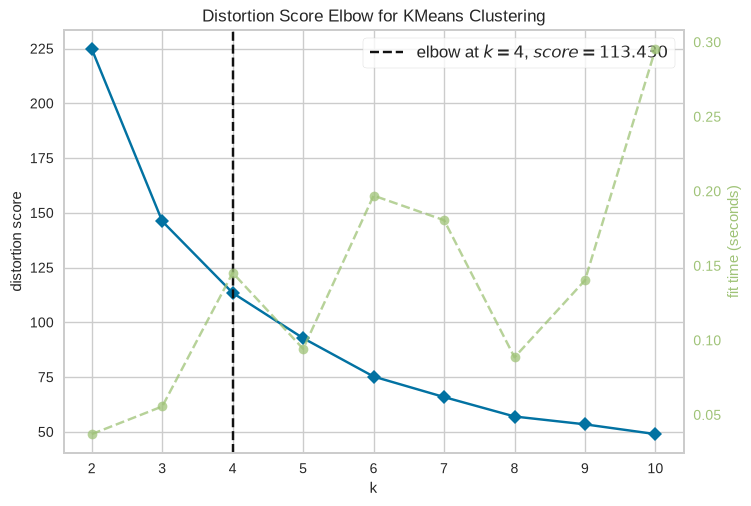

<Axes: title={'center': 'Distortion Score Elbow for KMeans Clustering'}, xlabel='k', ylabel='distortion score'>

In [22]:
# importer KElbowVisualizer
from yellowbrick.cluster import KElbowVisualizer
# Instantier le modèle kmeans
kmeans_model = KMeans(init = 'random', max_iter=500, n_init=10, random_state=42)
# Instantier KElbowVisualizer
# force_model=True : yellowbrick 1.5 ne reconnaît plus KMeans comme modèle de clustering avec scikit-learn >= 1.6
Elbow_M = KElbowVisualizer(kmeans_model, k=10, force_model=True)
# Entrainement
Elbow_M.fit(x)
# Visualiser l'elbow
Elbow_M.show()

**La courbe chute très fortement jusqu'à k = 2, puis encore nettement jusqu'à k = 3, et s'aplatit ensuite.**
On retient **3 classes**, qui correspondent à trois façons d'interagir avec une publication : commenter,
aimer ou partager.

#### <font color = "bisque"> Appliquer Kmeans en utilisant le k optimal

In [23]:
# Instantier le modèle
kmeans_model = KMeans(n_clusters = 3, init = 'random', max_iter=500, n_init=10, random_state=42)
# Entrainer le modèle
kmeans_model.fit(x)

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'random'
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",10
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",500
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",42
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 9)","[[0.25,0

#### <font color = "bisque"> Prédiction

In [24]:
# Prédiction de la partition des données
kmeans_partition = kmeans_model.predict(x)
# Afficher la partition
kmeans_partition[:100]

array([2, 1, 2, 1, 1, 1, 2, 2, 1, 1, 1, 1, 1, 1, 1, 1, 0, 2, 2, 1, 1, 1,
       1, 1, 1, 1, 2, 2, 1, 2, 1, 1, 1, 1, 1, 1, 2, 1, 1, 2, 2, 1, 2, 2,
       1, 2, 1, 2, 2, 2, 1, 2, 1, 2, 2, 2, 2, 2, 2, 2, 1, 2, 1, 2, 1, 1,
       2, 2, 2, 2, 1, 2, 2, 2, 2, 1, 2, 1, 2, 1, 2, 2, 2, 2, 2, 1, 1, 1,
       1, 2, 2, 1, 1, 1, 1, 1, 1, 2, 2, 2], dtype=int32)

In [25]:
# Nombre d'observations dans chaque classe
val = pd.Series(kmeans_partition).value_counts()
val

1    5434
0     915
2     585
Name: count, dtype: int64

In [26]:
# Fonction de visualisation du diagramme en barre des nombres d'observations
def bar_plot(val):
  fig = px.bar(x = val.index.astype(str), y = val.values, color = val.index.astype(str), text_auto = True)
  fig.show()

In [27]:
# Visualiser le diagramme des nombres d'observations
bar_plot(val)

In [28]:
# Fonction de visualisation des classes
def scatter_plot(New_df, Pred):
  # render_mode='svg' : au-delà de 1 000 points, plotly passe en WebGL, non affiché dans VS Code sur cette machine
  fig = px.scatter(New_df, x='PC1', y='PC2', color=Pred.astype(str), render_mode='svg')
  fig.show()

In [29]:
# Visualiser les classes
scatter_plot(New_df, kmeans_partition)

##### <font color = "bisque"> Indice de silhouette de la partition du Kmeans

In [30]:
# Silhouette score
from sklearn.metrics import silhouette_score
sil_km = silhouette_score(x, kmeans_partition)
print(f"Silhouette score : {sil_km}")

Silhouette score : 0.7422772401617864


### <font color = "gold"> CAH

In [31]:
# Importer linkage et dendrogram
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

Avec près de 7 000 publications, un dendrogramme complet serait illisible. On affiche un dendrogramme
**tronqué** : seules les 30 dernières fusions sont dessinées, chaque feuille indiquant entre parenthèses le
nombre de publications qu'elle regroupe.

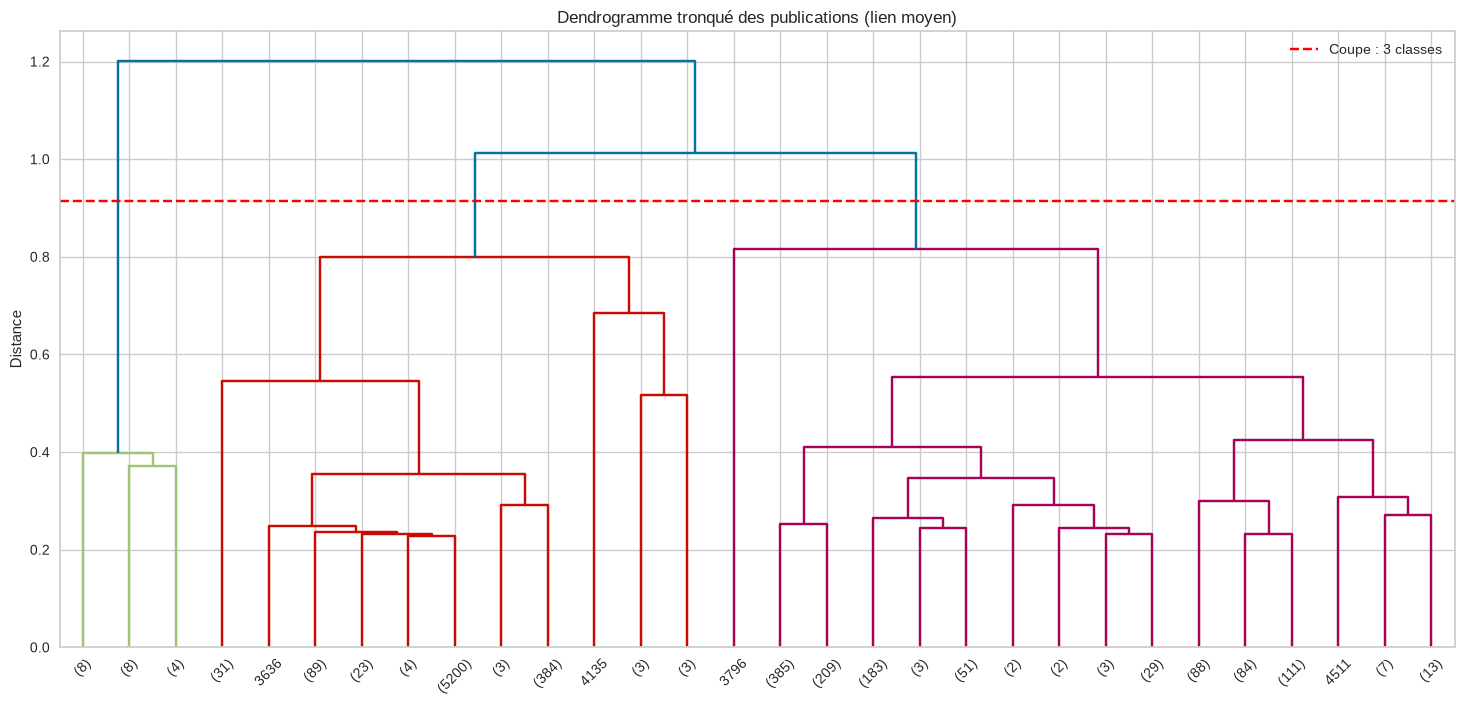

In [32]:
# Visualiser le dendrogramme (lien moyen, comme pour customer_segmentation)
Z = linkage(x, 'average') # matrice des liaisons
# Hauteur de coupe : entre la fusion qui donne 3 classes et celle qui donne 2 classes
seuil = (Z[-3, 2] + Z[-2, 2]) / 2
plt.figure(figsize=(18, 8))
dendro = dendrogram(Z, truncate_mode='lastp', p=30, color_threshold=seuil, leaf_font_size=10)
plt.axhline(y=seuil, color='red', linestyle='--', label='Coupe : 3 classes')
plt.title('Dendrogramme tronqué des publications (lien moyen)')
plt.ylabel('Distance')
plt.legend()
plt.show()

**En coupant au niveau de la ligne rouge, on obtient 3 classes, comme avec le Kmeans.**

In [33]:
from sklearn.cluster import AgglomerativeClustering
# Initier AgglomerativeClustering
cah_model = AgglomerativeClustering(n_clusters=3, linkage='average')
# Entrainer le modèle
cah_model.fit(x)

,"n_clusters n_clusters: int or None, default=2The number of clusters to find. It must be ``None`` if``distance_threshold`` is not ``None``.",3
,"linkage linkage: {'ward', 'complete', 'average', 'single'}, default='ward'Which linkage criterion to use. The linkage criterion determines whichdistance to use between sets of observation. The algorithm will mergethe pairs of cluster that minimize this criterion.- 'ward' minimizes the variance of the clusters being merged.- 'average' uses the average of the distances of each observation of the two sets.- 'complete' or 'maximum' linkage uses the maximum distances between all observations of the two sets.- 'single' uses the minimum of the distances between all observations of the two sets... versionadded:: 0.20 Added the 'single' optionFor examples comparing different `linkage` criteria, see:ref:`sphx_glr_auto_examples_cluster_plot_linkage_comparison.py`.",'average'
,"metric metric: str or callable, default=""euclidean""Metric used to compute the linkage. Can be ""euclidean"", ""l1"", ""l2"",""manhattan"", ""cosine"", or ""precomputed"". If linkage is ""ward"", only""euclidean"" and ""l2"" are accepted. If ""precomputed"", a distance matrix is neededas input for the fit method. If connectivity is None, linkage is""single"" and metric is not ""precomputed"" any valid pairwise distancemetric can be assigned.For an example of agglomerative clustering with different metrics, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_clustering_metrics.py`... versionadded:: 1.2",'euclidean'
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the output of the computation of the tree.By default, no caching is done. If a string is given, it is thepath to the caching directory.",None
,"connectivity connectivity: array-like, sparse matrix, or callable, default=NoneConnectivity matrix. Defines for each sample the neighboringsamples following a given structure of the data.This can be a connectivity matrix itself or a callable that transformsthe data into a connectivity matrix, such as derived from`kneighbors_graph`. Default is ``None``, i.e, thehierarchical clustering algorithm is unstructured.For an example of connectivity matrix using:class:`~sklearn.neighbors.kneighbors_graph`, see:ref:`sphx_glr_auto_examples_cluster_plot_ward_structured_vs_unstructured.py`.",None
,"compute_full_tree compute_full_tree: 'auto' or bool, default='auto'Stop early the construction of the tree at ``n_clusters``. This isuseful to decrease computation time if the number of clusters is notsmall compared to the number of samples. This option is useful onlywhen specifying a connectivity matrix. Note also that when varying thenumber of clusters and using caching, it may be advantageous to computethe full tree. It must be ``True`` if ``distance_threshold`` is not``None``. By default `compute_full_tree` is ""auto"", which is equivalentto `True` when `distance_threshold` is not `None` or that `n_clusters`is inferior to the maximum between 100 or `0.02 * n_samples`.Otherwise, ""auto"" is equivalent to `False`.",'auto'
,"distance_threshold distance_threshold: float, default=NoneThe linkage distance threshold at or above which clusters will not bemerged. If not ``None``, ``n_clusters`` must be ``None`` and``compute_full_tree`` must be ``True``... versionadded:: 0.21",None
,"compute_distances compute_distances: bool, default=FalseComputes distances between clusters even if `distance_threshold` is notused. This can be used to make dendrogram visualization, but introducesa computational and memory overhead... versionadded:: 0.24For an example of dendrogram visualization, see:ref:`sphx_glr_auto_examples_cluster_plot_agglomerative_dendrogram.py`.",False
Name,Type,Value
"children_ children_: array-like of shape (n_samples-1, 2)The children of each non-leaf node. Values less than `n_samples`correspond to leaves of the tree which are the original samples.A node `i` greater than or equal to `n_samp

In [34]:
# Prédire la partition des données
cah_partition = cah_model.fit_predict(x)
# Afficher la partition
cah_partition[:100]

array([0, 2, 0, 2, 2, 2, 0, 0, 2, 2, 2, 2, 2, 2, 2, 2, 0, 0, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 0, 2, 0, 2, 2, 2, 2, 2, 2, 0, 2, 2, 0, 2, 2, 2, 0,
       2, 0, 2, 2, 0, 0, 2, 2, 2, 0, 2, 0, 0, 2, 2, 0, 2, 0, 2, 0, 2, 2,
       0, 0, 2, 0, 2, 0, 0, 2, 0, 2, 0, 2, 0, 2, 2, 2, 0, 0, 0, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 0, 0, 0])

In [35]:
# Nombre d'observations dans chaque classe
val1 = pd.Series(cah_partition).value_counts()
val1

2    5742
0    1172
1      20
Name: count, dtype: int64

In [36]:
# Diagramme en barre des nombres d'observations
bar_plot(val1)

In [37]:
# Visualiser les classes
scatter_plot(New_df, cah_partition)

In [38]:
# Silhouette score
sil_cah = silhouette_score(x, cah_partition)
print(f"Silhouette score : {sil_cah}")

Silhouette score : 0.8157960242604212


### <font color = "gold"> Comparer Kmeans et CAH

In [39]:
# Diagramme en barre des silhouettes
Model_Names = ['KMEANS', 'CAH']
sil = [sil_km, sil_cah]
fig = px.bar(x = Model_Names, y = sil, color = Model_Names, text_auto = True)
fig.show()

**La CAH obtient un meilleur indice de silhouette que le Kmeans : c'est le modèle CAH que l'on déploie.**

### <font color = "gold"> Interpréter les classes

In [40]:
# Profil moyen de chaque classe (valeurs brutes)
profil = df.groupby(cah_partition).mean().round(1)
profil

,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys
0,309.9,1274.7,220.0,234.6,66.2,4.6,3.2,0.8,0.5
1,28.4,38.4,128.0,24.2,3.6,0.2,0.2,0.0,0.1
2,219.2,15.2,3.8,216.1,2.1,0.6,0.2,0.1,0.0


In [41]:
# Profil moyen de chaque classe (données normalisées : nature de l'engagement)
profil_norm = pd.DataFrame(x, columns=df.columns, index=df.index).groupby(cah_partition).mean().round(2)
profil_norm

,num_reactions,num_comments,num_shares,num_likes,num_loves,num_wows,num_hahas,num_sads,num_angrys
0,0.32,0.83,0.20,0.25,0.06,0.0,0.0,0.0,0.0
1,0.16,0.12,0.94,0.15,0.01,0.0,0.0,0.0,0.0
2,0.71,0.06,0.02,0.69,0.01,0.0,0.0,0.0,0.0


In [42]:
# Comparer les classes au type de publication
pd.crosstab(cah_partition, infos['status_type'].values, rownames=['Classe'], colnames=['Type'])

Type,link,photo,status,video
Classe,,,,
0,1,114,8,1049
1,0,9,0,11
2,62,4141,357,1182


**Interprétation :**
- une classe est dominée par les **commentaires** : ce sont presque toutes des **vidéos** (les directs
  « Facebook Live », où les clients commentent pour commander) ;
- une classe, de loin la plus grande, est dominée par les **j'aime** : on y trouve la quasi-totalité des
  **photos**, statuts et liens ;
- une petite classe est dominée par les **partages** : des publications diffusées par les abonnés, avec peu
  de réactions.

In [43]:
# Noms des classes : on regarde quel indicateur domine dans chaque classe
noms_classes = {}
noms_classes[profil_norm['num_comments'].idxmax()] = 'publication très commentée (type live vidéo)'
noms_classes[profil_norm['num_likes'].idxmax()] = 'publication surtout aimée (type photo)'
noms_classes[profil_norm['num_shares'].idxmax()] = 'publication surtout partagée'
noms_classes

{np.int64(0): 'publication très commentée (type live vidéo)',
 np.int64(2): 'publication surtout aimée (type photo)',
 np.int64(1): 'publication surtout partagée'}

In [44]:
# Les publications de chaque classe
cluster_names = []
for i in range(3):
  cluster_names.append(list(df.index[cah_partition == i]))
# Les publications de la plus petite classe
plus_petite = val1.idxmin()
print(cluster_names[plus_petite])

['Publication518', 'Publication535', 'Publication566', 'Publication700', 'Publication716', 'Publication2162', 'Publication4001', 'Publication4002', 'Publication4003', 'Publication4008', 'Publication4054', 'Publication4069', 'Publication4083', 'Publication4085', 'Publication4176', 'Publication4211', 'Publication4220', 'Publication4224', 'Publication4235', 'Publication4237']


### <font color = "gold"> Déploiement du meilleur modèle (CAH)

La CAH n'a pas de méthode `predict` : elle ne sait classer que les publications vues à l'entraînement. Pour
une **nouvelle** publication, on calcule le centre (centroïde) de chaque classe, puis on affecte la
publication à la classe dont le centroïde est le plus proche, comme dans `customer_segmentation`.

Le modèle est déployé dans l'**application Streamlit** commune aux deux nouveaux jeux de données
(`streamlit_app.py`, page « Publications Facebook », en ligne sur https://devoir-ml-clustering.streamlit.app).

In [45]:
from scipy.spatial.distance import cdist

# Calculer les centroïdes
classes = np.unique(cah_partition)
centroides = np.array([x[cah_partition == c].mean(axis=0) for c in classes])

# Prédiction : la classe du centroïde le plus proche
def predire_classe(nouvelle_publication):
    publication = normalize(np.array(nouvelle_publication, dtype=float).reshape(1, -1))
    distances = cdist(publication, centroides)
    return classes[distances.argmin()]

def affecter_publication(*valeurs):
    classe = predire_classe(valeurs)
    return "C'est une " + noms_classes[classe]

In [46]:
# Vérifier que les centroïdes retrouvent bien les classes de la CAH
predictions = np.array([predire_classe(ligne) for ligne in df.values])
print(f"Accord avec la CAH : {(predictions == cah_partition).mean():.1%}")

Accord avec la CAH : 99.4%


In [47]:
# Test sur une publication de chaque classe
for c in classes:
    i = np.where(cah_partition == c)[0][0]
    print(df.index[i], ':', affecter_publication(*df.iloc[i].values), '| classe CAH :', c)

Publication1 : C'est une publication très commentée (type live vidéo) | classe CAH : 0
Publication518 : C'est une publication surtout partagée | classe CAH : 1
Publication2 : C'est une publication surtout aimée (type photo) | classe CAH : 2


In [48]:
# Sauvegarder les centroïdes et les noms des classes (facultatif : l'application les recalcule à partir du CSV)
import joblib
joblib.dump({'centroides': centroides, 'classes': classes, 'noms_classes': noms_classes}, 'cah_facebook.joblib')

['cah_facebook.joblib']